# 3. TOPSIS — xếp hạng các phương án Pareto

Bước 3 của chuỗi **Demand → Multi-Objective Optimization → TOPSIS**.

- **Đọc:** `Model Outputs/pareto.parquet` (từ notebook 2): mỗi dòng là 1 phương án mạng lưới với giá trị `f1`, `f2`, `f3`.
- **Xếp hạng:** TOPSIS (scikit-criteria) với 4 kịch bản trọng số: Cost-driven, Service-driven, Green-driven (0.50 / 0.25 / 0.25) và Balanced (1/3 mỗi tiêu chí) (Decision_Log 6.4). Cả 3 tiêu chí đều là min.
- **Ghi:** `Model Outputs/topsis_ranking.parquet` + hình `figures/topsis_choices.png` (dùng mã ẩn danh).

In [1]:
# ===== SETUP =====
import pandas as pd                       # xử lý bảng
import numpy as np                        # tính toán
from pathlib import Path                  # ghép đường dẫn

OUT = Path("../Model Outputs")            # kết quả của các notebook model

pareto = pd.read_parquet(OUT / "pareto.parquet")                         # tập Pareto từ notebook 2
print(f"Số phương án Pareto: {len(pareto)}")

Số phương án Pareto: 39


## 3.1 Ma trận quyết định + 4 bộ trọng số

In [2]:
# ===== 3.1 MA TRẬN QUYẾT ĐỊNH + 4 BỘ TRỌNG SỐ =====
import warnings
import skcriteria as skc
from skcriteria.agg.topsis import TOPSIS
from skcriteria.preprocessing.scalers import VectorScaler
from skcriteria.pipelines import mkpipe

# --- Ma trận quyết định: mỗi hàng 1 phương án Pareto, 3 cột = 3 tiêu chí (đều càng NHỎ càng tốt) ---
TIEU_CHI = ["f1", "f2_gio", "f3"]                                        # chi phí (tỷ IDR/năm), thời gian giao (giờ/pallet), CO2 (tấn/năm)
mt = pareto.set_index("PhuongAn")[TIEU_CHI]
print(mt.head(10).round(2).to_string())

# --- 4 kịch bản trọng số (Decision_Log 6.4) ---
# Mỗi quan điểm quản lý 1 kịch bản: tiêu chí ưu tiên 0.50 (nặng bằng 2 tiêu chí kia cộng lại), 2 tiêu chí còn lại 0.25;
# thêm Balanced (bằng nhau) làm mốc trung lập
KICH_BAN = {"Cost-driven":    [0.50, 0.25, 0.25],
            "Service-driven": [0.25, 0.50, 0.25],
            "Green-driven":   [0.25, 0.25, 0.50],
            "Balanced":       [1 / 3, 1 / 3, 1 / 3]}
trong_so = pd.DataFrame(KICH_BAN, index=TIEU_CHI).T
assert np.allclose(trong_so.sum(axis=1), 1), "Trọng số mỗi kịch bản phải cộng lại = 1"
print("\nTrọng số theo kịch bản:")
print(trong_so.round(3).to_string())

              f1  f2_gio       f3
PhuongAn                         
P01       301.98    5.02  2748.71
P02       302.27    4.61  2686.33
P03       302.59    4.61  2673.01
P04       303.06    4.41  2662.64
P05       303.34    4.41  2648.89
P06       303.73    4.20  2630.58
P07       304.05    4.27  2622.64
P08       304.10    4.20  2613.61
P09       304.15    4.26  2606.99
P10       304.17    4.20  2606.99

Trọng số theo kịch bản:
                   f1  f2_gio     f3
Cost-driven     0.500   0.250  0.250
Service-driven  0.250   0.500  0.250
Green-driven    0.250   0.250  0.500
Balanced        0.333   0.333  0.333


## 3.2 TOPSIS + xếp hạng

In [3]:
# ===== 3.2 TOPSIS + XẾP HẠNG =====
# Các bước TOPSIS (Hwang & Yoon, 1981):
#   (1) chuẩn hoá vector từng cột (chia cho căn tổng bình phương) -> 3 tiêu chí khác đơn vị về cùng thang
#   (2) nhân trọng số của kịch bản
#   (3) điểm lý tưởng = giá trị NHỎ nhất mỗi cột (cả 3 tiêu chí càng nhỏ càng tốt); điểm tệ nhất = LỚN nhất
#   (4) khoảng cách Euclid từ mỗi phương án tới điểm lý tưởng (d+) và điểm tệ nhất (d-)
#   (5) điểm TOPSIS C = d- / (d+ + d-): từ 0 đến 1, càng gần 1 càng tốt -> hạng 1 = C lớn nhất
pipe = mkpipe(VectorScaler(target="matrix"), TOPSIS())                  # (1) chuẩn hoá vector, rồi (2)-(5) TOPSIS

ket_qua = []
for ten, w in KICH_BAN.items():
    dm = skc.mkdm(mt.to_numpy(), [min, min, min], weights=w, alternatives=list(mt.index), criteria=TIEU_CHI)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                                  # skcriteria nhắc về tiêu chí min; TOPSIS gốc xử lý tiêu chí chi phí bằng điểm lý tưởng = min
        kq = pipe.evaluate(dm)

    # --- Kiểm tra: tính tay đúng 5 bước trên, phải ra cùng điểm với skcriteria ---
    x = mt.to_numpy()
    v = x / np.sqrt((x ** 2).sum(axis=0)) * np.array(w)                 # (1) + (2)
    d_tot = np.sqrt(((v - v.min(axis=0)) ** 2).sum(axis=1))             # (3) + (4) tới điểm lý tưởng
    d_xau = np.sqrt(((v - v.max(axis=0)) ** 2).sum(axis=1))             #           tới điểm tệ nhất
    C = d_xau / (d_tot + d_xau)                                          # (5)
    assert np.allclose(C, kq.e_.similarity), f"{ten}: skcriteria khác tính tay"

    ket_qua.append(pd.DataFrame({"PhuongAn": mt.index, "KichBan": ten, "DiemTOPSIS": C, "Hang": kq.rank_}))
xh = pd.concat(ket_qua, ignore_index=True)
print("Kiểm tra tính tay = skcriteria: OK")

# --- Bảng hạng: mỗi phương án 1 hàng, mỗi kịch bản 1 cột (xếp theo hạng Balanced) ---
bang_hang = (xh.pivot(index="PhuongAn", columns="KichBan", values="Hang")[list(KICH_BAN)]
               .join(pareto.set_index("PhuongAn")[["f1", "f2_gio", "f3", "SoKhoMo"]])
               .sort_values("Balanced"))
print("\nHạng của từng phương án (1 = tốt nhất), 10 phương án đầu theo Balanced:")
print(bang_hang.head(10).round({"f1": 2, "f2_gio": 2, "f3": 0}).to_string())

# --- Top 3 mỗi kịch bản ---
for ten in KICH_BAN:
    t = xh[(xh["KichBan"] == ten) & (xh["Hang"] <= 3)].sort_values("Hang").merge(pareto, on="PhuongAn")
    print(f"\n{ten}:")
    print(t[["Hang", "PhuongAn", "DiemTOPSIS", "f1", "f2_gio", "f3", "SoKhoMo"]].round({"DiemTOPSIS": 3, "f1": 2, "f2_gio": 2, "f3": 0}).to_string(index=False))

xh.merge(pareto.drop(columns=["KhoMo"]), on="PhuongAn").to_parquet(OUT / "topsis_ranking.parquet", index=False)

Kiểm tra tính tay = skcriteria: OK

Hạng của từng phương án (1 = tốt nhất), 10 phương án đầu theo Balanced:
          Cost-driven  Service-driven  Green-driven  Balanced      f1  f2_gio      f3  SoKhoMo
PhuongAn                                                                                      
P35                 8               4             1         1  326.10    3.18  2550.0     50.0
P34                 2               3             3         2  324.25    3.18  2579.0     48.0
P32                 1               5             6         3  323.54    3.18  2605.0     47.0
P31                 3               6             8         4  323.29    3.18  2622.0     45.0
P37                16               7             2         5  334.93    3.18  2522.0     52.0
P38                17               1            11         6  342.17    2.97  2644.0     49.0
P39                18               2            10         7  343.06    2.97  2635.0     52.0
P30                 9               8

## 3.3 So sánh giữa các kịch bản

Không quét độ nhạy trọng số (Decision_Log 6.4). So sánh 4 kịch bản đã định: phương án hạng 1 của mỗi quan điểm, phương án lọt top 3 ở nhiều kịch bản, và mức giống nhau của các bảng xếp hạng.

Phương án hạng 1 của mỗi kịch bản:
       KichBan  DiemTOPSIS PhuongAn     f1  f2_gio     f3  SoKhoMo  DC Direct  DC Satellite  DEPO
   Cost-driven       0.762      P32 323.54    3.18 2605.0     47.0          6            15    16
Service-driven       0.881      P38 342.17    2.97 2644.0     49.0          7            18    14
  Green-driven       0.817      P35 326.10    3.18 2550.0     50.0          6            17    17
      Balanced       0.832      P35 326.10    3.18 2550.0     50.0          6            17    17

Phương án lọt top 3 (số kịch bản):
                                                     TopTrong  SoKichBan
PhuongAn                                                                
P34       Cost-driven, Service-driven, Green-driven, Balanced          4
P32                                     Cost-driven, Balanced          2
P35                                    Green-driven, Balanced          2
P31                                               Cost-driven          1
P

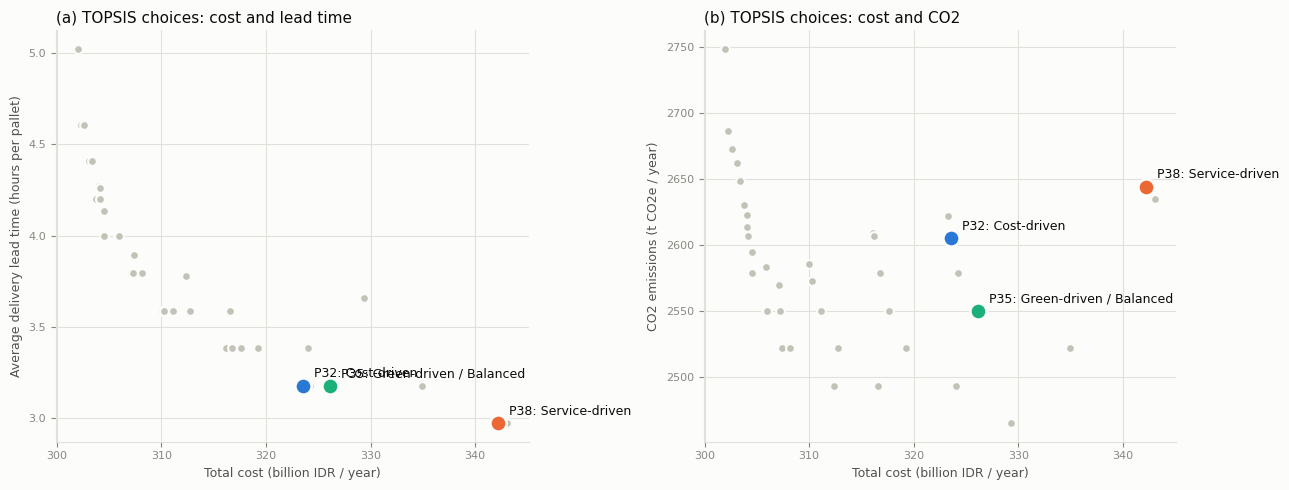

In [4]:
# ===== 3.3 SO SÁNH GIỮA CÁC KỊCH BẢN =====
# Không quét độ nhạy trọng số (Decision_Log 6.4): so sánh 4 kịch bản đã định -> mỗi quan điểm chọn mạng nào, có trùng nhau không
import matplotlib.pyplot as plt

# --- (a) Phương án hạng 1 của mỗi kịch bản ---
COT = ["PhuongAn", "f1", "f2_gio", "f3", "SoKhoMo", "DC Direct", "DC Satellite", "DEPO"]
hang1 = xh[xh["Hang"] == 1].merge(pareto[COT], on="PhuongAn")[["KichBan", "DiemTOPSIS"] + COT]
print("Phương án hạng 1 của mỗi kịch bản:")
print(hang1.round({"DiemTOPSIS": 3, "f1": 2, "f2_gio": 2, "f3": 0}).to_string(index=False))

# --- (b) Phương án lọt top 3 ở nhiều kịch bản = lựa chọn ít phụ thuộc quan điểm ---
top3 = xh[xh["Hang"] <= 3].groupby("PhuongAn")["KichBan"].agg(lambda s: ", ".join(s)).rename("TopTrong")
top3 = top3.to_frame().assign(SoKichBan=top3.str.count(",") + 1).sort_values("SoKichBan", ascending=False)
print("\nPhương án lọt top 3 (số kịch bản):")
print(top3.head(10).to_string())

# --- (c) Các kịch bản xếp hạng giống nhau đến đâu (tương quan hạng Spearman, 1 = giống hệt) ---
print("\nTương quan hạng giữa các kịch bản (Spearman):")
print(xh.pivot(index="PhuongAn", columns="KichBan", values="Hang")[list(KICH_BAN)].corr(method="spearman").round(2).to_string())

# --- (d) Hình: tập Pareto (chấm xám) + phương án hạng 1 của mỗi kịch bản (màu theo kịch bản) ---
MAU_KB = {"Cost-driven": "#2a78d6", "Service-driven": "#eb6834", "Green-driven": "#1baf7a", "Balanced": "#eda100"}
NEN, CHU, PHU, MO, LUOI = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=NEN)
for ax, y, ten_y in [(axes[0], "f2_gio", "Average delivery lead time (hours per pallet)"),
                     (axes[1], "f3", "CO2 emissions (t CO2e / year)")]:
    ax.scatter(pareto["f1"], pareto[y], s=40, color="#c3c2b7", edgecolors=NEN, linewidths=1.5, zorder=2, label="Pareto option")
    for pa, nhom in hang1.groupby("PhuongAn"):                          # 1 phương án có thể là hạng 1 của nhiều kịch bản
        r = pareto[pareto["PhuongAn"] == pa].iloc[0]
        ten_kb = list(nhom["KichBan"])
        ax.scatter(r["f1"], r[y], s=140, color=MAU_KB[ten_kb[0]], edgecolors=NEN, linewidths=2, zorder=3)
        ax.annotate(f"{pa}: " + " / ".join(ten_kb), (r["f1"], r[y]), xytext=(8, 6), textcoords="offset points",
                    fontsize=9, color=CHU)
    ax.set_xlabel("Total cost (billion IDR / year)", color=PHU, fontsize=9)
    ax.set_ylabel(ten_y, color=PHU, fontsize=9)
    ax.set_facecolor(NEN)
    ax.grid(True, color=LUOI, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(LUOI)
    ax.tick_params(colors=MO, labelsize=8)
axes[0].set_title("(a) TOPSIS choices: cost and lead time", loc="left", color=CHU, fontsize=11)
axes[1].set_title("(b) TOPSIS choices: cost and CO2", loc="left", color=CHU, fontsize=11)
fig.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
fig.savefig(OUT / "figures" / "topsis_choices.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# ===== 3.4 BẢN CHỤP KẾT QUẢ: CHÉP BẢN ĐỌC ĐƯỢC VÀO Model Outputs/12-10-2026 =====
# Bản chính vẫn ở Model Outputs/. Thư mục ngày chỉ là bản sao để đọc / gửi (CSV UTF-8 có BOM để Excel đọc đúng tiếng Việt).
import shutil
SNAP = OUT / "12-10-2026"
SNAP.mkdir(exist_ok=True)
pd.read_parquet(OUT / "topsis_ranking.parquet").to_csv(SNAP / "topsis_ranking.csv", index=False, encoding="utf-8-sig")
shutil.copy2(OUT / "figures" / "topsis_choices.png", SNAP / "topsis_choices.png")

WindowsPath('../Model Outputs/12-10-2026/topsis_choices.png')